In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [2]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv('predictive maintenance.csv')

print("Dataset Loaded Successfully!")
print(df.head())

Saving predictive maintenance.csv to predictive maintenance.csv
Dataset Loaded Successfully!
   UDI Product ID Type  Air temperature [K]  Process temperature [K]  \
0    1     M14860    M                298.1                    308.6   
1    2     L47181    L                298.2                    308.7   
2    3     L47182    L                298.1                    308.5   
3    4     L47183    L                298.2                    308.6   
4    5     L47184    L                298.2                    308.7   

   Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  Machine failure  TWF  \
0                    1551         42.8                0                0    0   
1                    1408         46.3                3                0    0   
2                    1498         49.4                5                0    0   
3                    1433         39.5                7                0    0   
4                    1408         40.0                9              

In [3]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nMachine Type Distribution:")
print(df['Type'].value_counts())

Dataset Shape: (10000, 14)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      100

In [4]:
X = df[['Type',
        'Air temperature [K]',
        'Process temperature [K]',
        'Rotational speed [rpm]',
        'Tool wear [min]']]

y = df['Torque [Nm]']

print("Input Features:", X.shape)
print("Target Variable:", y.shape)

Input Features: (10000, 5)
Target Variable: (10000,)


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (8000, 5)
Testing Data: (2000, 5)


In [6]:
preprocessor = ColumnTransformer(
    transformers=[
        ('type', OneHotEncoder(drop='first',
                               handle_unknown='ignore'),
         ['Type'])
    ],
    remainder='passthrough'
)

model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

model.fit(X_train, y_train)

print("Multiple Linear Regression Model Trained Successfully!")

Multiple Linear Regression Model Trained Successfully!


In [7]:
y_pred = model.predict(X_test)

print("Actual Values:", y_test.values[:10])
print("Predicted Values:", y_pred[:10].round(2))

Actual Values: [36.1 44.8 42.  33.7 23.9 45.9 51.1 51.1 36.2 34.6]
Predicted Values: [40.07 45.91 42.63 37.76 24.46 46.68 44.32 49.99 36.24 40.12]


In [8]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Multiple Linear Regression Performance")
print("---------------------------------------")

print("MAE  :", round(mae, 4))
print("MSE  :", round(mse, 4))
print("RMSE :", round(rmse, 4))
print("R2 Score:", round(r2, 4))

print("R2 Accuracy:", round(r2 * 100, 2), "%")

Multiple Linear Regression Performance
---------------------------------------
MAE  : 3.6866
MSE  : 23.9845
RMSE : 4.8974
R2 Score: 0.7566
R2 Accuracy: 75.66 %


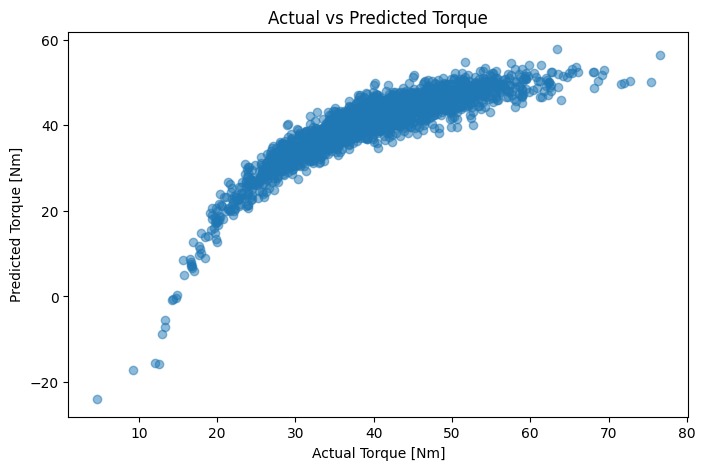

In [9]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual Torque [Nm]")
plt.ylabel("Predicted Torque [Nm]")

plt.title("Actual vs Predicted Torque")

plt.show()

In [10]:
new_machine = pd.DataFrame({
    'Type': ['M'],
    'Air temperature [K]': [300.5],
    'Process temperature [K]': [310.2],
    'Rotational speed [rpm]': [1500],
    'Tool wear [min]': [100]
})

prediction = model.predict(new_machine)

print("New Machine Conditions:")
print(new_machine)

print("\nPredicted Machine Torque:",
      round(prediction[0], 2), "Nm")

New Machine Conditions:
  Type  Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  \
0    M                300.5                    310.2                    1500   

   Tool wear [min]  
0              100  

Predicted Machine Torque: 41.91 Nm
